# Курсовая: эмбеддинги новостей и процесс Орнштейна–Уленбека

Идея в трёх строках. Каждый день из новостей получается вектор «удара» $\varepsilon_t$. Этот удар падает в «бак» скрытого состояния $x_t$, который постепенно забывает прошлое. Из бака читается то, что видно на рынке — в основном **доходность**, не сырая цена.

$$
x_{t+\Delta t}=A^{\Delta t}x_t+\varepsilon_t,\qquad
y_t \approx g_0+\langle g,x_t\rangle.
$$

$A$ сжимающая (всё забывается), $\varepsilon_t$ считается **заранее** и дальше не учится вместе с $A$ и $g$. Иначе одно и то же поведение можно получить поворотом координат, и параметры неразличимы.


## План тетради

1. **Синтетика.** Сами генерируем мир из модели и проверяем, что код находит $\lambda$ и $g$ обратно. Без этого любой слабый результат на рынке можно списать на баг.
2. **Уточнение модели.** Почему $y_t$ — доходность, а не цена; зачем календарный шаг $\Delta t$; почему эмбеддинг фиксирован.
3. **Лестница на реальных данных.** Сначала бейзлайны без новостей, потом всё более богатые $\varepsilon_t$ и $A$. На следующий шаг переходим только после оценки предыдущего.

Датасет уже собран (`dataset.ipynb`). Расчёты — в `scripts/ou.py` и `scripts/embed.py`.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scripts.build_dataset import ensure_dataset
from scripts import embed as E
from scripts import ou as OU

# --- что считаем на реальных данных (синтетика этими константами не пользуется)
TICKER = "^GSPC"          # S&P 500 — главная серия курсовой
SAMPLE_START, SAMPLE_END = "1990-01-01", "2018-12-31"
TRAIN_END, VAL_END = "2008-12-31", "2013-12-31"   # test = 2014–2018
D_EMB = 8                 # размерность после PCA (tf-idf / SBERT)
RIDGE = 1e-2
RNG = np.random.default_rng(0)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "font.size": 10})


# 1. Проверка на синтетике

Самый полезный шаг. Мы **знаем** правду: $A=\lambda I$ с $\lambda=0.9$, вектор $g$ и сами удары $\varepsilon_t$. Считаем $x_t$ и наблюдаем

$$
y_t=\langle g,x_t\rangle+\text{шум}.
$$

Если программа не возвращает $\lambda$ и направление $g$, чинить нужно код, а не модель мира. Доля выходных задаётся календарём Mon–Fri: после пятницы $\Delta t=3$, и затухание равно $\lambda^3$, не $\lambda^1$.


λ = 0.9,  выходных шагов dt=3: 20%
реализованный R² без шума 1.000, со шумом 0.531


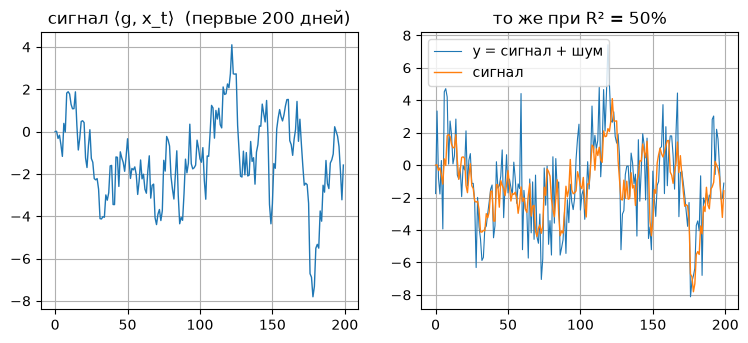

In [2]:
# мир, который мы сами придумали
d, T_syn, lam_true = 4, 1500, 0.9
g_true = RNG.normal(size=d); g_true = g_true / np.linalg.norm(g_true)

sim0 = OU.simulate(T_syn, d, lam_true, g_true, r2=1.0, weekends=True, seed=1)   # без шума
sim  = OU.simulate(T_syn, d, lam_true, g_true, r2=0.50, weekends=True, seed=1)  # половина дисперсии — сигнал

fig, ax = plt.subplots(1, 2)
ax[0].plot(sim0["signal"][:200], lw=1)
ax[0].set_title("сигнал ⟨g, x_t⟩  (первые 200 дней)")
ax[1].plot(sim["y"][:200], lw=0.8, label="y = сигнал + шум")
ax[1].plot(sim["signal"][:200], lw=1, label="сигнал")
ax[1].legend(); ax[1].set_title("то же при R² = 50%")
print(f"λ = {lam_true},  выходных шагов dt=3: {(sim['dt']==3).mean():.0%}")
print(f"реализованный R² без шума {sim0['r2']:.3f}, со шумом {sim['r2']:.3f}")


## 1.1. Находит ли код $\lambda$ и $g$?

Эмбеддинг здесь **известен** (это наши $\varepsilon_t$). Для каждого кандидата $\lambda$ бак $x_t$ считается однозначно, $g$ — обычная регрессия. Рисуем ошибку как функцию $\lambda$: минимум должен сесть на $0.9$.


без шума : λ̂ = 0.900   cos(ĝ, g) = 1.000
R² = 50% : λ̂ = 0.900   cos(ĝ, g) = 1.000
Если λ̂ ≈ 0.9 и косинус ≈ 1 — код в порядке.


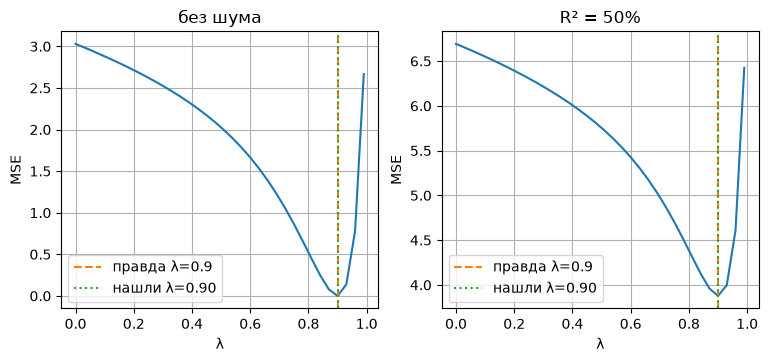

In [3]:
train_syn = np.ones(T_syn, dtype=bool)
fit0 = OU.fit_scalar_grid(sim0["eps"], sim0["y"], sim0["dt"], train_syn)
fit  = OU.fit_scalar_grid(sim["eps"],  sim["y"],  sim["dt"],  train_syn)

def plot_grid(fit, title, ax):
    ax.plot(fit["grid"]["lam"], fit["grid"]["train_mse"])
    ax.axvline(lam_true, color="C1", ls="--", label=f"правда λ={lam_true}")
    ax.axvline(fit["lam"], color="C2", ls=":", label=f"нашли λ={fit['lam']:.2f}")
    ax.set_xlabel("λ"); ax.set_ylabel("MSE"); ax.set_title(title); ax.legend()

fig, ax = plt.subplots(1, 2)
plot_grid(fit0, "без шума", ax[0])
plot_grid(fit,  "R² = 50%", ax[1])
print("без шума : λ̂ = {:.3f}   cos(ĝ, g) = {:.3f}".format(fit0["lam"], OU.cosine(g_true, fit0["g"])))
print("R² = 50% : λ̂ = {:.3f}   cos(ĝ, g) = {:.3f}".format(fit["lam"],  OU.cosine(g_true, fit["g"])))
print("Если λ̂ ≈ 0.9 и косинус ≈ 1 — код в порядке.")


## 1.2. Сколько сигнала нужно?

На финансовых доходностях модель, которая объясняет $0.1$–$1\%$ дисперсии, уже неплохо. Крутим долю сигнала и смотрим, ломается ли оценка $\lambda$. $T=2000$ дней ≈ 8 лет.


In [4]:
rec = OU.recovery_by_noise(T=2000, d=4, lam=0.9, seed=0, weekends=True)
display(rec.round(3))
print("Правило чтения: пока cos(g) высокий, а |λ̂−0.9| маленький — метод ещё видит сигнал.")


,r2_target,r2_realized,lam_true,lam_hat,abs_err_lam,cos_g,fit_r2
0,1.000,1.000,0.9,0.90,0.00,1.000,1.000
1,0.500,0.500,0.9,0.90,0.00,0.998,0.499
2,0.100,0.100,0.9,0.87,0.03,0.998,0.082
3,0.010,0.010,0.9,0.93,0.03,0.959,0.017
4,0.005,0.005,0.9,0.93,0.03,0.914,0.007
5,0.001,0.001,0.9,0.90,0.00,0.832,0.001


Правило чтения: пока cos(g) высокий, а |λ̂−0.9| маленький — метод ещё видит сигнал.


## 1.3. Нужен ли датасет больше?

Фиксируем слабый сигнал $R^2=0.5\%$ (середина «финансового» диапазона) и спрашиваем: при какой длине выборки сетка уверенно отличает $\lambda=0.9$ от $\lambda=0.5$? Это прямой ответ на «хватит ли наших ~6500 торговых дней».


,T,years,mean_lam,std_lam,p_closer_to_true,p_above_mid
0,250,1.0,0.634,0.335,0.500,0.500
1,500,2.0,0.670,0.277,0.625,0.625
2,1000,4.0,0.675,0.302,0.625,0.625
3,2000,7.9,0.810,0.239,0.875,0.875
4,4000,15.9,0.896,0.034,1.000,1.000
5,6500,25.8,0.889,0.048,1.000,1.000


Если при T=6500 вероятность всё ещё ~0.5 — на реальном рынке ждать чуда не стоит,
нужен либо более сильный сигнал, либо другая цель (например |r|, не знак доходности).


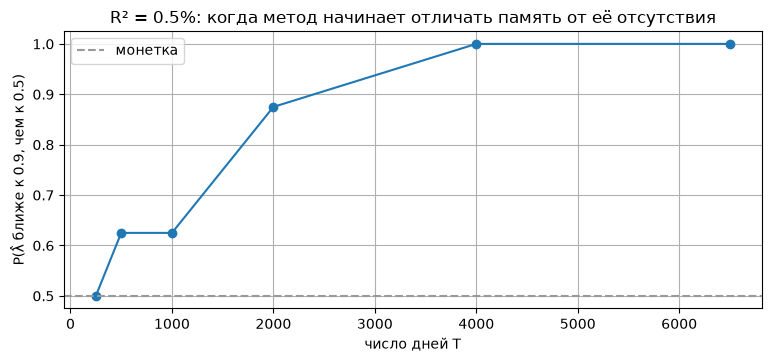

In [5]:
pwr = OU.power_lambda(lam_true=0.9, lam_alt=0.5, r2=0.005,
                      Ts=(250, 500, 1000, 2000, 4000, 6500), n_rep=8, d=4, seed=0)
display(pwr.round(3))
fig, ax = plt.subplots()
ax.plot(pwr["T"], pwr["p_closer_to_true"], marker="o")
ax.axhline(0.5, color="0.6", ls="--", label="монетка")
ax.set_xlabel("число дней T"); ax.set_ylabel("P(λ̂ ближе к 0.9, чем к 0.5)")
ax.set_title("R² = 0.5%: когда метод начинает отличать память от её отсутствия")
ax.legend()
print("Если при T=6500 вероятность всё ещё ~0.5 — на реальном рынке ждать чуда не стоит,")
print("нужен либо более сильный сигнал, либо другая цель (например |r|, не знак доходности).")


# 2. Что именно оцениваем

Три решения, без которых формула $p_t=\langle g,x_t\rangle$ на ценах ломается.


## 2.1. Доходность, а не цена

Если $A$ сжимающая, $x_t$ стационарен — значит $\langle g,x_t\rangle$ тоже. **Цены не стационарны**: они копят информацию. Поэтому основной объект —

$$
r_t=\Delta\log p_t \approx g_0+\langle g,x_t\rangle.
$$

Цена тогда получается как интеграл от $r$. Два контрольных варианта ниже: лог-цена минус скользящее среднее (локально стационарная «буквальная» $p_t$) и предельный случай $\lambda\to 1$, когда бак почти не забывает и сам становится похож на цену.


## 2.2. Эмбеддинг не учим вместе с $A$ и $g$

Пока $\varepsilon_t$ фиксирован, $x_t$ — детерминированная функция новостей и $A$. Задача сводится к регрессии. Если крутить эмбеддинг, $A$ и $g$ одновременно, одно и то же $y$ получается поворотом координат. Поэтому: сначала текст → $\varepsilon_t$ (на train), потом динамика.


## 2.3. Выходные — это больший шаг

Между пятницей и понедельником три календарных дня. Правильное затухание $\lambda^{\Delta t}$, а не всегда $\lambda^1$. Ниже — та же синтетика: один раз с честным $\Delta t$, один раз с «все шаги = 1».


In [6]:
sim_w = OU.simulate(1500, 4, 0.9, g_true, r2=0.5, weekends=True, seed=2)
tr = np.ones(1500, dtype=bool)
ok  = OU.fit_scalar_grid(sim_w["eps"], sim_w["y"], sim_w["dt"], tr)
bad = OU.fit_scalar_grid(sim_w["eps"], sim_w["y"], np.ones(1500), tr)
print(f"честный Δt : λ̂ = {ok['lam']:.3f}")
print(f"все шаги = 1: λ̂ = {bad['lam']:.3f}   (сдвиг — плата за игнор выходных)")


честный Δt : λ̂ = 0.900
все шаги = 1: λ̂ = 0.870   (сдвиг — плата за игнор выходных)


# 3. Реальные данные

Одна строка на торговый день NYSE. Окно эксперимента: **1990 → 2018** (train 1990–2008, val 2009–2013, test 2014–2018). Новость с `trading_date = D` была публична **до закрытия** дня $D$ — подглядывания в будущее нет.

Два окна прогноза:

* **next-day** (основное, торгуемое): в $x_t$ входят новости до закрытия $t-1$, предсказываем $y_t$;
* **same-day**: в $x_t$ доливаем ещё новости дня $t$ (это уже не ставка с вечера, а «объясняет ли лента сегодняшний $r$»).


In [7]:
paths = ensure_dataset()
daily = pd.read_parquet(paths["daily"])
wide  = pd.read_parquet(paths["prices_wide"])
daily["date"] = pd.to_datetime(daily["date"])
cut = (daily["date"] >= SAMPLE_START) & (daily["date"] <= SAMPLE_END)
daily = daily.loc[cut].reset_index(drop=True)
dates = pd.DatetimeIndex(daily["date"])
wide  = wide.reindex(dates)
dt    = OU.calendar_dt(dates)

masks = OU.split_masks(dates, TRAIN_END, VAL_END)
train, val, test = masks["train"], masks["val"], masks["test"]
texts = daily["finance_text"].fillna("").astype(str)

r      = OU.target(wide, TICKER, "logret")
y_r    = r
y_abs  = OU.target(wide, TICKER, "logabs")
y_ma   = OU.target(wide, TICKER, "logp_ma")
vix    = wide["^VIX"].astype(float).to_numpy()
vlag   = np.concatenate([[np.nan], vix[:-1]])

print(f"{TICKER}: {dates[0].date()} → {dates[-1].date()}  ({len(dates)} дней)")
print(f"train {int(train.sum())}  val {int(val.sum())}  test {int(test.sum())}")
print(f"выходных/праздничных шагов dt>1: {(dt>1).mean():.1%}, средний dt={dt.mean():.2f}")


14:23:28 INFO scripts.build_dataset: processed files exist but do not cover 1990-01-01 -> today; rebuilding


14:23:36 INFO scripts.news: HF mirror 1990: 98905 articles, 12 month(s) where the Kaggle mirror is short


14:23:36 WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


14:23:38 INFO scripts.news: HF mirror 1991: 85588 articles, 12 month(s) where the Kaggle mirror is short


14:23:40 INFO scripts.news: HF mirror 1992: 86038 articles, 12 month(s) where the Kaggle mirror is short


...

14:29:06 INFO scripts.market: CL=F       6567 rows  2000-08-23 -> 2026-10-19


14:29:06 INFO scripts.market: HG=F       6563 rows  2000-08-30 -> 2026-10-19


14:29:06 INFO scripts.build_dataset: common period 1990-01-02 -> 2025-12-31: 9067 trading days


14:29:18 INFO scripts.build_dataset: done: 1714338 articles (561335 finance), 29 tickers, 9067 trading days -> C:\Users\mperi\news-embed-for-finance-prediction\data\processed


^GSPC: 1990-01-02 → 2018-12-31  (7307 дней)
train 4791  val 1258  test 1258
выходных/праздничных шагов dt>1: 21.7%, средний dt=1.45


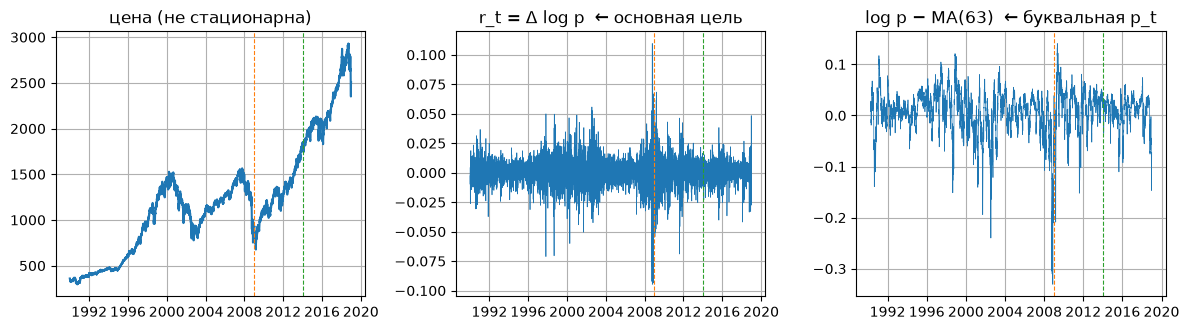

In [8]:
# почему не цена: уровни лезут вверх, доходность — нет
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot(dates, wide[TICKER]); ax[0].set_title("цена (не стационарна)")
ax[1].plot(dates, y_r, lw=0.5); ax[1].set_title("r_t = Δ log p  ← основная цель")
ax[2].plot(dates, y_ma, lw=0.5); ax[2].set_title("log p − MA(63)  ← буквальная p_t")
for a in ax:
    a.axvline(pd.Timestamp(TRAIN_END), color="C1", ls="--", lw=0.8)
    a.axvline(pd.Timestamp(VAL_END), color="C2", ls="--", lw=0.8)
plt.tight_layout()


# 4. Бейзлайны без новостей

Пока новости не открываем. Если «умная» модель не бьёт эти ряды, новости ничего не добавили.

| имя | что это |
|---|---|
| `mean` | среднее $y$ по train |
| `lag` | вчерашний $y$ |
| `abs_lag` | вчерашний $|r|$ |
| `ewma` | тот же бак, но «доливают» сами $|r|$, $\lambda=0.94$ |
| `har` | средние $y$ за 1, 5, 22 дня |
| `vix` | лаг VIX (implied vol) |
| `garch` | GARCH(1,1) по $r$ |

Все используют только информацию до $t-1$. Считаем для $r_t$ и для $\log(|r_t|+\epsilon)$.


In [9]:
def baseline_table(y, title):
    fc = OU.baseline_forecasts(y, r, vix, train, dt=dt)
    rows = [OU.eval_row(k, y, yh, train, val, test) for k, yh in fc.items()]
    tab = pd.DataFrame(rows).set_index("model")[["train_r2", "val_r2", "test_r2", "test_ic"]]
    print(title)
    display(tab.round(4))
    return fc, tab

fc_r,   tab_r   = baseline_table(y_r,   f"цель: r_t  ({TICKER} logret)")
fc_abs, tab_abs = baseline_table(y_abs, f"цель: log(|r_t|+ε)")
print("Ожидание: знак r_t почти непредсказуем (R² около нуля). |r| частично берётся VIX/HAR.")


цель: r_t  (^GSPC logret)


,train_r2,val_r2,test_r2,test_ic
model,,,,
mean,0.0000,-0.0009,-0.0000,NaN
lag,0.0024,0.0050,-0.0016,0.0085
har,0.0061,0.0028,-0.0001,0.0403
garch,0.0004,-0.0003,0.0001,0.0184
vix,0.0001,-0.0003,0.0004,0.0389
abs_lag,0.0027,-0.0008,-0.0023,0.0078
ewma,0.0000,-0.0010,-0.0001,-0.0352


цель: log(|r_t|+ε)


,train_r2,val_r2,test_r2,test_ic
model,,,,
mean,0.0000,-0.0025,-0.0750,-0.0000
lag,0.0147,0.0030,-0.0461,0.1093
har,0.1203,0.0973,0.0497,0.2373
garch,0.0745,0.0577,0.0464,0.2932
vix,0.1541,0.1251,0.1358,0.3826
abs_lag,0.0261,0.0015,-0.0257,0.1943
ewma,0.1151,0.1022,0.0530,0.2854


Ожидание: знак r_t почти непредсказуем (R² около нуля). |r| частично берётся VIX/HAR.


# 5. Лестница: новости

Правило: один шаг — одно усложнение, сравнение с предыдущим шагом и с бейзлайнами. Эмбеддинг всегда fit на train, динамика — тоже.

Порядок эмбеддингов: **число статей → лексический сентимент → TF-IDF+PCA → SBERT**. Число статей — контрольный признак: если оно объясняет столько же, сколько «умные» векторы, дело в активности ленты, не в смысле.

Порядок $A$: **$\lambda=0$ (нет памяти) → скаляр $\lambda I$ → диагональ → полная $A$** с $\rho(A)<1$.


In [10]:
ladder = []  # копим строки сравнения

def add_news(name, eps, y, *, lam=None, include_today=False, ridge=RIDGE, extra=None):
    """Скалярная A: λ=0 или сетка по val."""
    if lam is None:
        fit = OU.fit_scalar_grid(eps, y, dt, train, val, test, ridge=ridge,
                                 include_today=include_today)
        lam_used, yhat, x = fit["lam"], fit["yhat"], fit["x"]
        extra_fit = {"lam": lam_used}
    else:
        x = OU.states(eps, lam, dt, kind="scalar", include_today=include_today)
        g0, g = OU.fit_observation(x[train], y[train], ridge=ridge)
        yhat, lam_used = OU.predict(x, g0, g), lam
        extra_fit = {"lam": lam_used}
    row = OU.eval_row(name, y, yhat, train, val, test, extra={**(extra or {}), **extra_fit})
    ladder.append(row)
    return dict(x=x, yhat=yhat, lam=lam_used, row=row)


def show_ladder():
    cols = ["model", "lam", "train_r2", "val_r2", "test_r2", "test_ic"]
    tab = pd.DataFrame(ladder)
    keep = [c for c in cols if c in tab.columns]
    display(tab[keep].round(4))
    return tab


## 5.1. Контроль: сколько финансовых статей за день

Один признак, без семантики. Сначала память выключена ($\lambda=0$): сегодняшняя доходность объясняется только вчерашним числом статей. Потом разрешаем бак помнить.


без памяти λ=0     test R²=-0.0020
сетка выбрала λ=0.00  test R²=-0.0020  IC=-0.0152


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.0,0.0002,-0.0016,-0.002,-0.0152
1,count / λ-grid / r / next,0.0,0.0002,-0.0016,-0.002,-0.0152


Если val R² как у mean — лента как счётчик не двигает r_t. Идём дальше, не усложняя A.


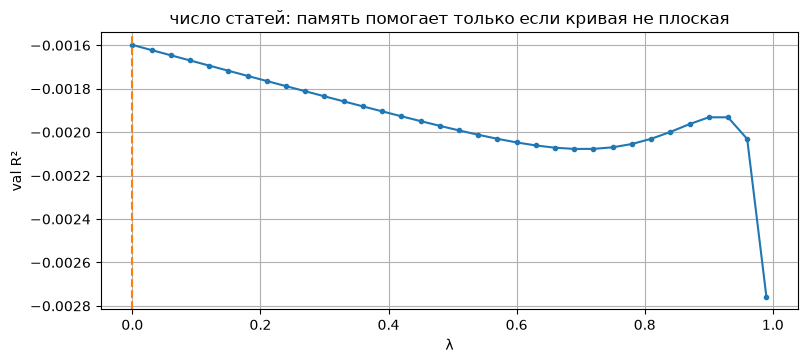

In [11]:
eps_n = OU.standardize_train(np.log1p(daily["n_finance"].to_numpy(float))[:, None], train)

# цель — доходность r_t, окно next-day
m00 = add_news("count / λ=0 / r / next", eps_n, y_r, lam=0.0)
m0g = add_news("count / λ-grid / r / next", eps_n, y_r)
print(f"без памяти λ=0     test R²={m00['row']['test_r2']:.4f}")
print(f"сетка выбрала λ={m0g['lam']:.2f}  test R²={m0g['row']['test_r2']:.4f}  IC={m0g['row']['test_ic']:.4f}")

fig, ax = plt.subplots()
fit_n = OU.fit_scalar_grid(eps_n, y_r, dt, train, val, test, ridge=RIDGE)
ax.plot(fit_n["grid"]["lam"], fit_n["grid"]["val_r2"], marker="o", ms=3)
ax.axvline(fit_n["lam"], color="C1", ls="--")
ax.set_xlabel("λ"); ax.set_ylabel("val R²")
ax.set_title("число статей: память помогает только если кривая не плоская")
show_ladder()
print("Если val R² как у mean — лента как счётчик не двигает r_t. Идём дальше, не усложняя A.")


## 5.2. Тот же счётчик, но цель — амплитуда

Знак доходности почти белый шум. $|r|$ ближе к «рынку нервничает». Если новости вообще работают, это должно быть видно здесь раньше, чем на $r_t$.


In [12]:
m_abs0 = add_news("count / λ=0 / log|r| / next", eps_n, y_abs, lam=0.0)
m_absg = add_news("count / λ-grid / log|r| / next", eps_n, y_abs)
print("для сравнения, лучший бейзлайн log|r| на test:")
print(tab_abs["test_r2"].sort_values(ascending=False).head(3).round(4).to_string())
show_ladder()


для сравнения, лучший бейзлайн log|r| на test:
model
vix     0.1358
ewma    0.0530
har     0.0497


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.00,0.0002,-0.0016,-0.0020,-0.0152
1,count / λ-grid / r / next,0.00,0.0002,-0.0016,-0.0020,-0.0152
2,count / λ=0 / log|r| / next,0.00,0.0002,0.0011,-0.0622,0.0834
3,count / λ-grid / log|r| / next,0.93,0.0007,0.0089,-0.0308,0.0787


,model,train_r2,train_ic,train_mse,val_r2,val_ic,val_mse,test_r2,test_ic,test_mse,lam
0,count / λ=0 / r / next,0.000246,0.015686,0.000129,-0.001598,-0.016895,0.000151,-0.001979,-0.015239,0.000070,0.00
1,count / λ-grid / r / next,0.000246,0.015686,0.000129,-0.001598,-0.016895,0.000151,-0.001979,-0.015239,0.000070,0.00
2,count / λ=0 / log|r| / next,0.000155,0.012434,1.277867,0.001097,0.163030,1.400245,-0.062198,0.083371,1.451049,0.00
3,count / λ-grid / log|r| / next,0.000742,0.027231,1.277117,0.008920,0.167611,1.389278,-0.030758,0.078708,1.408100,0.93


## 5.3. Лексический сентимент

Три числа на день: длина текста, доля негативных слов, полярность (короткий finance-словарь). Всё ещё без «понимания» предложений — но уже не голый счётчик.


In [13]:
eps_s, info_s = E.fit_embeddings(texts, train, method="sentiment", d=3, reduce="pca")
print("сентимент:", info_s.get("names", info_s.get("vectorizer")))
m_s_r   = add_news("sent / λ-grid / r / next",     eps_s, y_r)
m_s_abs = add_news("sent / λ-grid / log|r| / next", eps_s, y_abs)
show_ladder()
print("Сравнивать sent с count: если R² тот же — смысл слов не добавил, добавила активность.")


14:29:33 INFO scripts.embed: embeddings sentiment -> PCA d=3 (train=4791 days, raw_dim=3)


сентимент: ['log_len', 'neg_share', 'polarity']


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.00,0.0002,-0.0016,-0.0020,-0.0152
1,count / λ-grid / r / next,0.00,0.0002,-0.0016,-0.0020,-0.0152
2,count / λ=0 / log|r| / next,0.00,0.0002,0.0011,-0.0622,0.0834
3,count / λ-grid / log|r| / next,0.93,0.0007,0.0089,-0.0308,0.0787
4,sent / λ-grid / r / next,0.00,0.0007,-0.0050,-0.0192,-0.0056
5,sent / λ-grid / log|r| / next,0.00,0.0324,-0.0028,-0.1255,0.0606


Сравнивать sent с count: если R² тот же — смысл слов не добавил, добавила активность.


## 5.4. TF-IDF + PCA (и PLS)

Мешок слов с весами. PCA — поворот на train **без** $y$ (честный эмбеддинг). PLS смотрит на train-$y$: это уже подсказка цели, но $A$ и эмбеддинг всё ещё не крутятся вместе.


In [14]:
eps_tfidf, info_tfidf = E.fit_embeddings(texts, train, method="tfidf", d=D_EMB, reduce="pca")
print("TF-IDF PCA:", {k: info_tfidf[k] for k in ("d", "vocab", "explained_variance_sum") if k in info_tfidf})
m_tf_r   = add_news("tfidf-pca / λ-grid / r / next",     eps_tfidf, y_r)
m_tf_abs = add_news("tfidf-pca / λ-grid / log|r| / next", eps_tfidf, y_abs)

eps_pls, _ = E.fit_embeddings(texts, train, method="tfidf", d=D_EMB, reduce="pls", y=y_abs)
m_pls_abs = add_news("tfidf-pls / λ-grid / log|r| / next", eps_pls, y_abs)
show_ladder()
print("PLS имеет право быть сильнее PCA на train/val; на test смотрим, не съела ли подсказка обобщение.")


14:30:57 INFO scripts.embed: embeddings tfidf -> TruncatedSVD d=8 (train=4791 days, raw_dim=50000)


TF-IDF PCA: {'d': 8, 'vocab': 50000, 'explained_variance_sum': 0.04240435904362176}


14:32:53 INFO scripts.embed: embeddings tfidf -> PLS+SVD256 d=8 (train=4791 days, raw_dim=50000)


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.00,0.0002,-0.0016,-0.0020,-0.0152
1,count / λ-grid / r / next,0.00,0.0002,-0.0016,-0.0020,-0.0152
2,count / λ=0 / log|r| / next,0.00,0.0002,0.0011,-0.0622,0.0834
3,count / λ-grid / log|r| / next,0.93,0.0007,0.0089,-0.0308,0.0787
4,sent / λ-grid / r / next,0.00,0.0007,-0.0050,-0.0192,-0.0056
5,sent / λ-grid / log|r| / next,0.00,0.0324,-0.0028,-0.1255,0.0606
6,tfidf-pca / λ-grid / r / next,0.00,0.0030,-0.0199,-0.0514,0.0168
7,tfidf-pca / λ-grid / log|r| / next,0.15,0.0843,0.0251,-0.0394,0.0626
8,tfidf-pls / λ-grid / log|r| / next,0.81,0.1493,0.0398,-0.0014,0.0720


PLS имеет право быть сильнее PCA на train/val; на test смотрим, не съела ли подсказка обобщение.


## 5.5. SBERT

Готовый sentence-transformer, дневной текст → вектор, затем PCA на train. Кэш лежит в `data/processed/embeddings/`. Если вдруг модели нет — шаг пропускаем: лестница уже сравнима без него.


In [15]:
try:
    eps_bert, info_bert = E.fit_embeddings(
        texts, train, method="sbert", d=D_EMB, reduce="pca", dates=dates,
    )
    print("SBERT", {k: info_bert[k] for k in ("d", "vectorizer", "explained_variance_sum") if k in info_bert})
    m_b_r   = add_news("sbert / λ-grid / r / next",     eps_bert, y_r)
    m_b_abs = add_news("sbert / λ-grid / log|r| / next", eps_bert, y_abs)
except Exception as exc:
    eps_bert, m_b_abs = None, None
    print("SBERT пропущен:", exc)
show_ladder()


14:33:24 INFO sentence_transformers.base.model: No device provided, using cpu


14:33:25 INFO sentence_transformers.base.model: Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

14:33:29 INFO scripts.embed: encoding 7307 daily blobs with sentence-transformers/all-MiniLM-L6-v2 (truncated to model window)


Batches:   0%|          | 0/115 [00:00<?, ?it/s]

14:36:46 INFO scripts.embed: embeddings sbert -> PCA d=8 (train=4791 days, raw_dim=384)


SBERT {'d': 8, 'vectorizer': 'sentence-transformers/all-MiniLM-L6-v2', 'explained_variance_sum': 0.2060727065537229}


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.00,0.0002,-0.0016,-0.0020,-0.0152
1,count / λ-grid / r / next,0.00,0.0002,-0.0016,-0.0020,-0.0152
2,count / λ=0 / log|r| / next,0.00,0.0002,0.0011,-0.0622,0.0834
3,count / λ-grid / log|r| / next,0.93,0.0007,0.0089,-0.0308,0.0787
4,sent / λ-grid / r / next,0.00,0.0007,-0.0050,-0.0192,-0.0056
5,sent / λ-grid / log|r| / next,0.00,0.0324,-0.0028,-0.1255,0.0606
6,tfidf-pca / λ-grid / r / next,0.00,0.0030,-0.0199,-0.0514,0.0168
7,tfidf-pca / λ-grid / log|r| / next,0.15,0.0843,0.0251,-0.0394,0.0626
8,tfidf-pls / λ-grid / log|r| / next,0.81,0.1493,0.0398,-0.0014,0.0720
9,sbert / λ-grid / r / next,0.00,0.0009,0.0012,0.0004,0.0232


,model,train_r2,train_ic,train_mse,val_r2,val_ic,val_mse,test_r2,test_ic,test_mse,lam
0,count / λ=0 / r / next,0.000246,0.015686,0.000129,-0.001598,-0.016895,0.000151,-0.001979,-0.015239,0.000070,0.00
1,count / λ-grid / r / next,0.000246,0.015686,0.000129,-0.001598,-0.016895,0.000151,-0.001979,-0.015239,0.000070,0.00
2,count / λ=0 / log|r| / next,0.000155,0.012434,1.277867,0.001097,0.163030,1.400245,-0.062198,0.083371,1.451049,0.00
3,count / λ-grid / log|r| / next,0.000742,0.027231,1.277117,0.008920,0.167611,1.389278,-0.030758,0.078708,1.408100,0.93
4,sent / λ-grid / r / next,0.000683,0.026126,0.000129,-0.005049,0.006878,0.000151,-0.019193,-0.005552,0.000071,0.00
5,sent / λ-grid / log|r| / next,0.032410,0.180028,1.236643,-0.002774,0.070406,1.405670,-0.125536,0.060581,1.537574,0.00
6,tfidf-pca / λ-grid / r / next,0.002975,0.054543,0.000129,-0.019863,0.014941,0.000153,-0.051357,0.016792,0.000073,0.00
7,tfidf-pca / λ-grid / log|r| / next,0.084304,0.290351,1.170319,0.025081,0.185230,1.366624,-0.039376,0.062565,1.419872,0.15
8,tfidf-pls / λ-grid / log|r| / next,0.149293,0.386384,1.087259,0.039807,0.242305,1.345981,-0.001421,0.071980,1.368023,0.81
9,sbert / λ-grid / r / next,0.000949,0.030809,0.000129,0.001186,0.061032,0.000150,0.000357,0.023169,0.000070,0.00


## 5.6. Динамика $A$: диагональ и полная матрица

До сих пор $A=\lambda I$ — все компоненты забываются одинаково. Берём **лучший эмбеддинг по val R² на $\log|r|$** (там сигнал, если он есть, должен быть) и разрешаем:

* диагональ — своя скорость забывания на каждую координату;
* полную $A$ с $\rho(A)<1$: $A=\rho\cdot M/\|M\|_2$, $\rho<0.99$. Сначала scipy, затем тот же приём градиентом (PyTorch).


In [16]:
# лучший эмбеддинг на val для log|r|, next-day, скалярная λ
cands = [
    ("count", eps_n),
    ("sent", eps_s),
    ("tfidf-pca", eps_tfidf),
    ("tfidf-pls", eps_pls),
]
if eps_bert is not None:
    cands.append(("sbert", eps_bert))

def val_r2_of(eps):
    fit = OU.fit_scalar_grid(eps, y_abs, dt, train, val, ridge=RIDGE)
    return fit["lam"], fit["val"]["r2"], fit

picked_name, (picked_lam, picked_val, picked_fit) = None, (-1, -np.inf, None)
for name, eps in cands:
    lam, v, fit = val_r2_of(eps)
    print(f"  {name:12s}  λ={lam:.2f}  val R²={v:.4f}")
    if v > picked_val:
        picked_name, picked_lam, picked_val, picked_fit = name, lam, v, fit
        picked_eps = eps
print(f"берём {picked_name}  (val R²={picked_val:.4f})")


  count         λ=0.93  val R²=0.0089


  sent          λ=0.00  val R²=-0.0028


  tfidf-pca     λ=0.15  val R²=0.0251


  tfidf-pls     λ=0.81  val R²=0.0398


  sbert         λ=0.99  val R²=0.0180
берём tfidf-pls  (val R²=0.0398)


In [17]:
# диагональная A
diag = OU.fit_dynamics(picked_eps, y_abs, dt, train, val, kind="diag", ridge=RIDGE)
diag["test"] = OU.metrics(y_abs[test], diag["yhat"][test])
ladder.append(OU.eval_row(f"{picked_name} / A=diag / log|r| / next",
                          y_abs, diag["yhat"], train, val, test,
                          extra={"lam": float(np.median(diag["lam"]))}))
print("diag λ", np.round(diag["lam"], 3), "half-life (дни)", np.round(diag["half_life"], 2))
print("test R²={r2:.4f}  IC={ic:.4f}".format(**diag["test"]))

# полная A, scipy (спектральная норма). Больше 4 компонент — слишком много свободных чисел на слабый сигнал.
eps_full = picked_eps[:, : min(4, picked_eps.shape[1])]
full = OU.fit_dynamics(eps_full, y_abs, dt, train, val, kind="full", ridge=RIDGE, maxiter=40)
full["test"] = OU.metrics(y_abs[test], full["yhat"][test])
ladder.append(OU.eval_row(f"{picked_name} / A=full / log|r| / next",
                          y_abs, full["yhat"], train, val, test,
                          extra={"lam": full["spectral_radius"]}))
print(f"full ρ(A)={full['spectral_radius']:.3f}  |eig|={np.round(full['lam'], 3)}")
print("test R²={r2:.4f}  IC={ic:.4f}".format(**full["test"]))
show_ladder()
print("Диагональ/полная A имеют право выиграть на train и проиграть на test — тогда оставляем скаляр.")


diag λ [0.925 0.502 0.495 0.483 0.5   0.483 0.489 0.493] half-life (дни) [8.85 1.01 0.99 0.95 1.   0.95 0.97 0.98]
test R²=-0.0314  IC=0.0466


full ρ(A)=0.923  |eig|=[0.923 0.085 0.05  0.05 ]
test R²=-0.1882  IC=-0.0104


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.0000,0.0002,-0.0016,-0.0020,-0.0152
1,count / λ-grid / r / next,0.0000,0.0002,-0.0016,-0.0020,-0.0152
2,count / λ=0 / log|r| / next,0.0000,0.0002,0.0011,-0.0622,0.0834
3,count / λ-grid / log|r| / next,0.9300,0.0007,0.0089,-0.0308,0.0787
4,sent / λ-grid / r / next,0.0000,0.0007,-0.0050,-0.0192,-0.0056
5,sent / λ-grid / log|r| / next,0.0000,0.0324,-0.0028,-0.1255,0.0606
6,tfidf-pca / λ-grid / r / next,0.0000,0.0030,-0.0199,-0.0514,0.0168
7,tfidf-pca / λ-grid / log|r| / next,0.1500,0.0843,0.0251,-0.0394,0.0626
8,tfidf-pls / λ-grid / log|r| / next,0.8100,0.1493,0.0398,-0.0014,0.0720
9,sbert / λ-grid / r / next,0.0000,0.0009,0.0012,0.0004,0.0232


Диагональ/полная A имеют право выиграть на train и проиграть на test — тогда оставляем скаляр.


In [18]:
# тот же приём градиентом (PyTorch), на синтетике: T маленький, правду знаем.
# A = ρ · M / ||M||_2 гарантирует ρ(A) < 1.
try:
    tr_s = np.ones(T_syn, dtype=bool)
    ft = OU.fit_full_torch(sim["eps"], sim["y"], sim["dt"], tr_s, tr_s,
                           ridge=0.0, steps=15, lr=0.05, seed=0)
    print(f"синтетика R²=50%: torch ρ(A)={ft['spectral_radius']:.3f}  fit R²={ft['train']['r2']:.3f}")
    print("|eig(A)| =", np.round(ft["lam"], 3), "  (скалярная правда была λ=0.9)")
except Exception as exc:
    print("torch-шаг пропущен:", exc)


синтетика R²=50%: torch ρ(A)=0.495  fit R²=0.241
|eig(A)| = [0.495 0.124 0.124 0.038]   (скалярная правда была λ=0.9)


## 5.7. Same-day vs next-day

До сих пор $x_t$ знал новости только до вчерашнего закрытия. Same-day доливает сегодняшнюю ленту в сегодняшний бак: это **объяснение**, не вечерняя ставка. Если same-day живой, а next-day мёртвый — новости связаны с рынком, но к открытию уже в цене.


In [19]:
for window, today in (("next", False), ("same", True)):
    add_news(f"{picked_name} / λ-grid / log|r| / {window}", picked_eps, y_abs, include_today=today)
    add_news(f"{picked_name} / λ-grid / r / {window}",     picked_eps, y_r,   include_today=today)
show_ladder()


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.0000,0.0002,-0.0016,-0.0020,-0.0152
1,count / λ-grid / r / next,0.0000,0.0002,-0.0016,-0.0020,-0.0152
2,count / λ=0 / log|r| / next,0.0000,0.0002,0.0011,-0.0622,0.0834
3,count / λ-grid / log|r| / next,0.9300,0.0007,0.0089,-0.0308,0.0787
4,sent / λ-grid / r / next,0.0000,0.0007,-0.0050,-0.0192,-0.0056
5,sent / λ-grid / log|r| / next,0.0000,0.0324,-0.0028,-0.1255,0.0606
6,tfidf-pca / λ-grid / r / next,0.0000,0.0030,-0.0199,-0.0514,0.0168
7,tfidf-pca / λ-grid / log|r| / next,0.1500,0.0843,0.0251,-0.0394,0.0626
8,tfidf-pls / λ-grid / log|r| / next,0.8100,0.1493,0.0398,-0.0014,0.0720
9,sbert / λ-grid / r / next,0.0000,0.0009,0.0012,0.0004,0.0232


,model,train_r2,train_ic,train_mse,val_r2,val_ic,val_mse,test_r2,test_ic,test_mse,lam
0,count / λ=0 / r / next,0.000246,0.015686,0.000129,-0.001598,-0.016895,0.000151,-0.001979,-0.015239,0.000070,0.000000
1,count / λ-grid / r / next,0.000246,0.015686,0.000129,-0.001598,-0.016895,0.000151,-0.001979,-0.015239,0.000070,0.000000
2,count / λ=0 / log|r| / next,0.000155,0.012434,1.277867,0.001097,0.163030,1.400245,-0.062198,0.083371,1.451049,0.000000
3,count / λ-grid / log|r| / next,0.000742,0.027231,1.277117,0.008920,0.167611,1.389278,-0.030758,0.078708,1.408100,0.930000
4,sent / λ-grid / r / next,0.000683,0.026126,0.000129,-0.005049,0.006878,0.000151,-0.019193,-0.005552,0.000071,0.000000
5,sent / λ-grid / log|r| / next,0.032410,0.180028,1.236643,-0.002774,0.070406,1.405670,-0.125536,0.060581,1.537574,0.000000
6,tfidf-pca / λ-grid / r / next,0.002975,0.054543,0.000129,-0.019863,0.014941,0.000153,-0.051357,0.016792,0.000073,0.000000
7,tfidf-pca / λ-grid / log|r| / next,0.084304,0.290351,1.170319,0.025081,0.185230,1.366624,-0.039376,0.062565,1.419872,0.150000
8,tfidf-pls / λ-grid / log|r| / next,0.149293,0.386384,1.087259,0.039807,0.242305,1.345981,-0.001421,0.071980,1.368023,0.810000
9,sbert / λ-grid / r / next,0.000949,0.030809,0.000129,0.001186,0.061032,0.000150,0.000357,0.023169,0.000070,0.000000


## 5.8. Два других прочтения $p_t=\langle g,x_t\rangle$

* лог-цена минус скользящее среднее — модель в буквальном виде, но на стационарном остатке;
* свободная $\lambda$ на $r_t$: если оценка лезет к $1$, бак хочет стать интегратором (как цена копит новости).


log p − MA : λ̂=0.00  test R²=-0.0303
r_t        : λ̂=0.93  (к 1 → хочет интегрировать; к 0 → новости живут один день)


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.0000,0.0002,-0.0016,-0.0020,-0.0152
1,count / λ-grid / r / next,0.0000,0.0002,-0.0016,-0.0020,-0.0152
2,count / λ=0 / log|r| / next,0.0000,0.0002,0.0011,-0.0622,0.0834
3,count / λ-grid / log|r| / next,0.9300,0.0007,0.0089,-0.0308,0.0787
4,sent / λ-grid / r / next,0.0000,0.0007,-0.0050,-0.0192,-0.0056
5,sent / λ-grid / log|r| / next,0.0000,0.0324,-0.0028,-0.1255,0.0606
6,tfidf-pca / λ-grid / r / next,0.0000,0.0030,-0.0199,-0.0514,0.0168
7,tfidf-pca / λ-grid / log|r| / next,0.1500,0.0843,0.0251,-0.0394,0.0626
8,tfidf-pls / λ-grid / log|r| / next,0.8100,0.1493,0.0398,-0.0014,0.0720
9,sbert / λ-grid / r / next,0.0000,0.0009,0.0012,0.0004,0.0232


,model,train_r2,train_ic,train_mse,val_r2,val_ic,val_mse,test_r2,test_ic,test_mse,lam
0,count / λ=0 / r / next,0.000246,0.015686,0.000129,-0.001598,-0.016895,0.000151,-0.001979,-0.015239,0.000070,0.000000
1,count / λ-grid / r / next,0.000246,0.015686,0.000129,-0.001598,-0.016895,0.000151,-0.001979,-0.015239,0.000070,0.000000
2,count / λ=0 / log|r| / next,0.000155,0.012434,1.277867,0.001097,0.163030,1.400245,-0.062198,0.083371,1.451049,0.000000
3,count / λ-grid / log|r| / next,0.000742,0.027231,1.277117,0.008920,0.167611,1.389278,-0.030758,0.078708,1.408100,0.930000
4,sent / λ-grid / r / next,0.000683,0.026126,0.000129,-0.005049,0.006878,0.000151,-0.019193,-0.005552,0.000071,0.000000
5,sent / λ-grid / log|r| / next,0.032410,0.180028,1.236643,-0.002774,0.070406,1.405670,-0.125536,0.060581,1.537574,0.000000
6,tfidf-pca / λ-grid / r / next,0.002975,0.054543,0.000129,-0.019863,0.014941,0.000153,-0.051357,0.016792,0.000073,0.000000
7,tfidf-pca / λ-grid / log|r| / next,0.084304,0.290351,1.170319,0.025081,0.185230,1.366624,-0.039376,0.062565,1.419872,0.150000
8,tfidf-pls / λ-grid / log|r| / next,0.149293,0.386384,1.087259,0.039807,0.242305,1.345981,-0.001421,0.071980,1.368023,0.810000
9,sbert / λ-grid / r / next,0.000949,0.030809,0.000129,0.001186,0.061032,0.000150,0.000357,0.023169,0.000070,0.000000


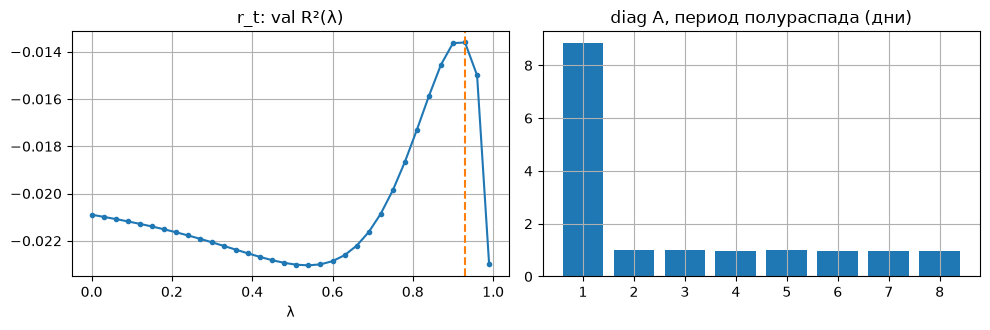

In [20]:
fit_ma = add_news(f"{picked_name} / λ-grid / logp-MA / next", picked_eps, y_ma)
grid_r = OU.fit_scalar_grid(picked_eps, y_r, dt, train, val, test, ridge=RIDGE)
print(f"log p − MA : λ̂={fit_ma['lam']:.2f}  test R²={fit_ma['row']['test_r2']:.4f}")
print(f"r_t        : λ̂={grid_r['lam']:.2f}  (к 1 → хочет интегрировать; к 0 → новости живут один день)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(grid_r["grid"]["lam"], grid_r["grid"]["val_r2"], marker="o", ms=3)
ax[0].axvline(grid_r["lam"], color="C1", ls="--")
ax[0].set_title("r_t: val R²(λ)"); ax[0].set_xlabel("λ")
ax[1].bar(np.arange(1, len(diag["half_life"]) + 1),
          np.where(np.isfinite(diag["half_life"]), diag["half_life"], 0))
ax[1].set_title("diag A, период полураспада (дни)")
plt.tight_layout()
show_ladder()


## 5.9. Добавляют ли новости что-то сверх HAR + VIX?

Вложенный тест Кларка–Веста на test: $H_0$ — новости не уменьшают ошибку сверх HAR и лага VIX. Положительный $t$ — новости помогают. Это главный «честный» критерий качества: обычный $R^2$ новости-только легко проигрывает VIX, даже если новости несут свой кусок.


In [21]:
# скалярная λ, выбранная по val, next-day, цель log|r|
x_best = picked_fit["x"]
nest = OU.nested_news(y_abs, x_best, train, test, controls=vlag, ridge=RIDGE)
cw = nest["clark_west"]
print("цель log|r|, next-day, эмбеддинг =", picked_name)
print("HAR+VIX           test R²={r2:.4f}  IC={ic:.4f}".format(**nest["restricted"]))
print("HAR+VIX+новости   test R²={r2:.4f}  IC={ic:.4f}".format(**nest["unrestricted"]))
print(f"Clark–West t={cw['t']:.2f}  p={cw['p']:.2e}   (H0: новости не добавляют)")

# то же для знака доходности — ожидание: пусто
nest_r = OU.nested_news(y_r, x_best, train, test, controls=vlag, ridge=RIDGE)
print("\nцель r_t:")
print("HAR+VIX           test R²={r2:.4f}".format(**nest_r["restricted"]))
print("HAR+VIX+новости   test R²={r2:.4f}".format(**nest_r["unrestricted"]),
      f"  CW t={nest_r['clark_west']['t']:.2f} p={nest_r['clark_west']['p']:.2e}")


цель log|r|, next-day, эмбеддинг = tfidf-pls
HAR+VIX           test R²=0.1079  IC=0.3594
HAR+VIX+новости   test R²=0.0551  IC=0.2811
Clark–West t=-2.51  p=9.94e-01   (H0: новости не добавляют)

цель r_t:
HAR+VIX           test R²=0.0004
HAR+VIX+новости   test R²=-0.0798   CW t=-0.00 p=5.01e-01


,decile,n,yhat,y
0,1,126,-5.893,-6.010
1,2,126,-5.824,-6.121
2,3,126,-5.778,-5.911
3,4,125,-5.738,-5.777
4,5,126,-5.704,-5.779
5,6,126,-5.671,-5.830
6,7,125,-5.634,-5.669
7,8,126,-5.587,-5.633
8,9,126,-5.525,-5.313
9,10,126,-5.371,-4.941


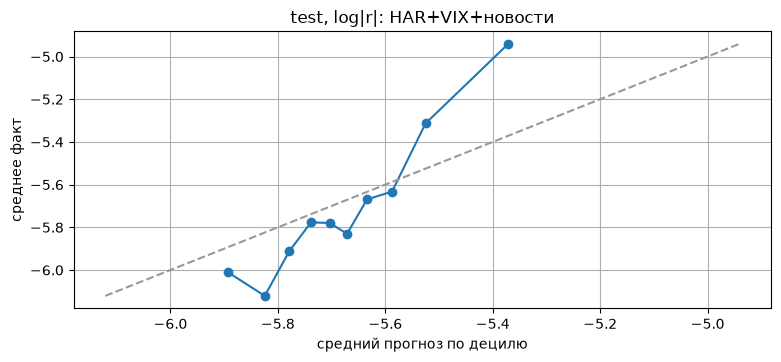

In [22]:
# калибровка лучшей вложенной модели на test (log|r|)
cal = OU.calibration_deciles(y_abs[test], nest["yhat_u"][test])
fig, ax = plt.subplots()
ax.plot(cal["yhat"], cal["y"], marker="o")
lim = [min(cal.yhat.min(), cal.y.min()), max(cal.yhat.max(), cal.y.max())]
ax.plot(lim, lim, color="0.6", ls="--")
ax.set_xlabel("средний прогноз по децилю"); ax.set_ylabel("среднее факт")
ax.set_title("test, log|r|: HAR+VIX+новости")
display(cal.round(3))


# 6. Как читать результаты

Короткий словарь, без самообмана.

* **Синтетика сошлась** — код не виноват. Дальше слабый $R^2$ на рынке это свойство задачи, не баг.
* **$r_t$ около нуля** — нормально: знак дневной доходности S&P почти непредсказуем. Имеет смысл смотреть $\log(|r|+\epsilon)$.
* **Счётчик статей ≈ SBERT** — модель ловит *сколько* написали, а не *что*.
* **Same-day живой, next-day нет** — новости связаны с днём, но к открытию уже в цене; торговать с вечера нельзя.
* **Clark–West незначим** — новости не бьют HAR+VIX. Их можно оставить как иллюстрацию динамики OU, но не как рабочий прогноз.
* **$\lambda\to 1$ на ценах и $\lambda$ маленькая на $r$** — бак на доходностях должен забывать; интегратор нужен самой цене.

Реализованной внутридневной волатильности в датасете нет, поэтому третий столбец целей из плана ($RV_t$) здесь не считается. Другое окно — овернайт до 9:30 на XLK — разобрано в `ou_model.ipynb`: там VIX слабее, и у заголовков появляется шанс.


In [23]:
final = show_ladder()
print("готово. Главные числа — test R² / IC и Clark–West в ячейке 5.9.")


,model,lam,train_r2,val_r2,test_r2,test_ic
0,count / λ=0 / r / next,0.0000,0.0002,-0.0016,-0.0020,-0.0152
1,count / λ-grid / r / next,0.0000,0.0002,-0.0016,-0.0020,-0.0152
2,count / λ=0 / log|r| / next,0.0000,0.0002,0.0011,-0.0622,0.0834
3,count / λ-grid / log|r| / next,0.9300,0.0007,0.0089,-0.0308,0.0787
4,sent / λ-grid / r / next,0.0000,0.0007,-0.0050,-0.0192,-0.0056
5,sent / λ-grid / log|r| / next,0.0000,0.0324,-0.0028,-0.1255,0.0606
6,tfidf-pca / λ-grid / r / next,0.0000,0.0030,-0.0199,-0.0514,0.0168
7,tfidf-pca / λ-grid / log|r| / next,0.1500,0.0843,0.0251,-0.0394,0.0626
8,tfidf-pls / λ-grid / log|r| / next,0.8100,0.1493,0.0398,-0.0014,0.0720
9,sbert / λ-grid / r / next,0.0000,0.0009,0.0012,0.0004,0.0232


готово. Главные числа — test R² / IC и Clark–West в ячейке 5.9.
